In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PortfolioOptimization import get_yearly_report

In [2]:
max_risk = 0.20
alloc_partitions = 20

In [3]:
output_dir = './Output/Change in Max Allocation'
os.makedirs(output_dir, exist_ok=True)
output_dir = f'{output_dir}/{alloc_partitions} Parts'
os.makedirs(output_dir, exist_ok=True)
os.makedirs(f'{output_dir}/Graphs', exist_ok=True)

In [4]:
from Portfolios.GSPCBuyAndHold import BuyAndHold
# from Portfolios.EqualWeights import EqWeightPortfolio
from Portfolios.Markowitz import MarkowitzPortfolio
from Portfolios.MeanAbsDev import MeanAbsDevPortfolio
# from Portfolios.MedAbsDev import MedianAbsDevPortfolio

portfolios = {
    'S&P BnH': BuyAndHold,
    # 'Equal': EqWeightPortfolio,
    'Markowitz': MarkowitzPortfolio,
    'MAD': MeanAbsDevPortfolio,
    # 'MedAD': MedianAbsDevPortfolio,
}

reports = {}

In [5]:
reports = {}
for i in range(1, alloc_partitions + 1):
    max_alloc = i / alloc_partitions
    reports[max_alloc] = {}
    for name, portfolio in portfolios.items():
        weights, stats = get_yearly_report(portfolio, max_risk, max_alloc=max_alloc)
        reports[max_alloc][name] = {
            'weights': weights,
            'stats': stats
        }
        stats_used = list(stats.columns)
        stats_used.remove('Year')

# Weight Analysis

In [6]:
# weights_collector = None
# for portfolio, report in reports.items():
#     weights = report['weights'].copy()
#     weights.columns = ['Year'] \
#                         + [(portfolio, column)
#                             for column in weights.columns
#                             if column != 'Year']
#     weights = weights.set_index('Year')

#     weights.columns = pd.MultiIndex.from_tuples(weights.columns)
    
#     if weights_collector is None:
#         weights_collector = weights
#     else:
#         weights_collector = pd.merge(
#                                 weights_collector,
#                                 weights,
#                                 left_index=True,
#                                 right_index=True
#                             )

# weights_collector.to_excel(f'{output_dir}/Weights.xlsx')

# Statistic Analysis

Export only Annual Return

In [7]:
stats_collector = None
for max_alloc, yearly_reports in reports.items():
    for portfolio, report in yearly_reports.items():
        stats = report['stats'].copy()[['Year', 'Annual Return']]
        stats.columns = ['Year'] \
                            + [(max_alloc, portfolio)
                                for column in stats.columns
                                if column != 'Year']
        stats = stats.set_index('Year')

        stats.columns = pd.MultiIndex.from_tuples(stats.columns)
        
        if stats_collector is None:
            stats_collector = stats
        else:
            stats_collector = pd.merge(
                                stats_collector, 
                                stats, 
                                left_index=True, 
                                right_index=True
                            )

stats_collector.to_excel(f'{output_dir}/Annual Return.xlsx')

baseline = 'S&P BnH'
delta_dict = {}
for i in range(1, alloc_partitions + 1):
    max_alloc = i / alloc_partitions
    for portfolio in portfolios.keys():
        if portfolio == baseline:
            continue
        delta_dict[(max_alloc, portfolio)] = \
                stats_collector[max_alloc, portfolio]\
                    # - stats_collector[max_alloc, baseline]

delta_df = pd.DataFrame(delta_dict)
# delta_df.index = pd.MultiIndex.from_tuples(delta_df.index)

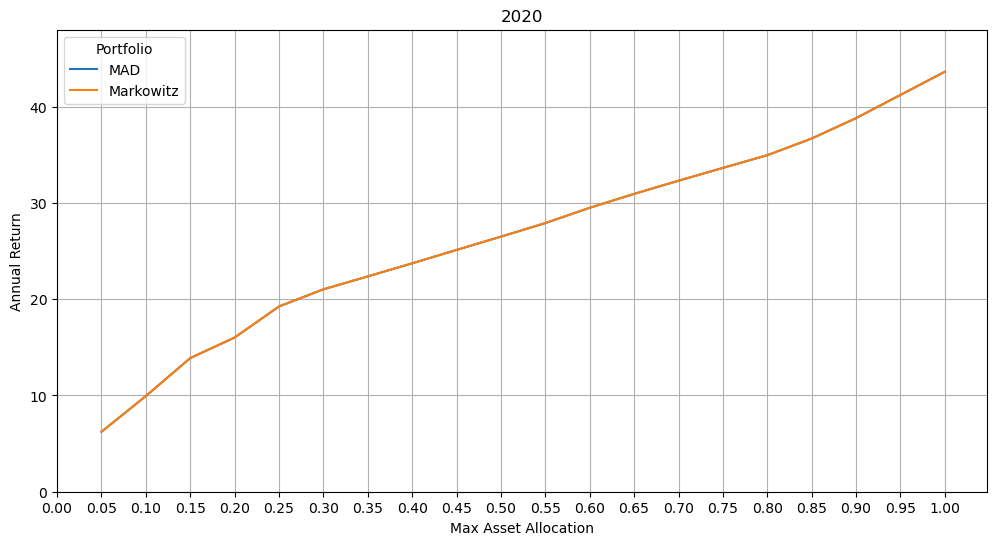

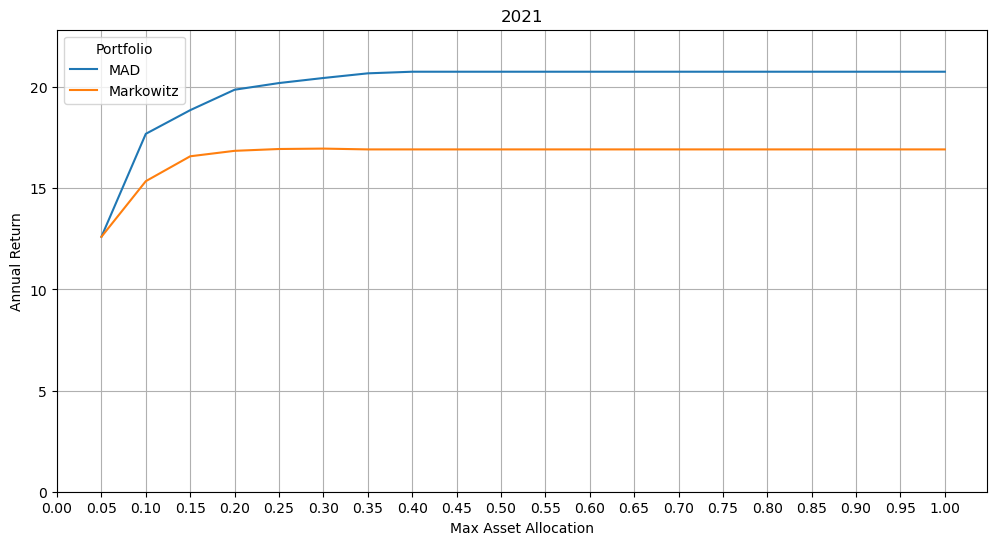

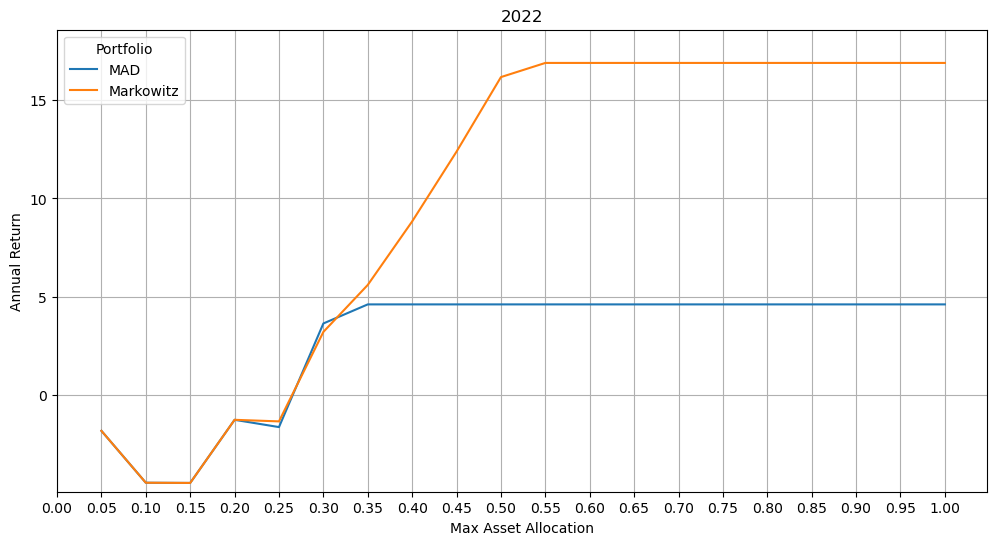

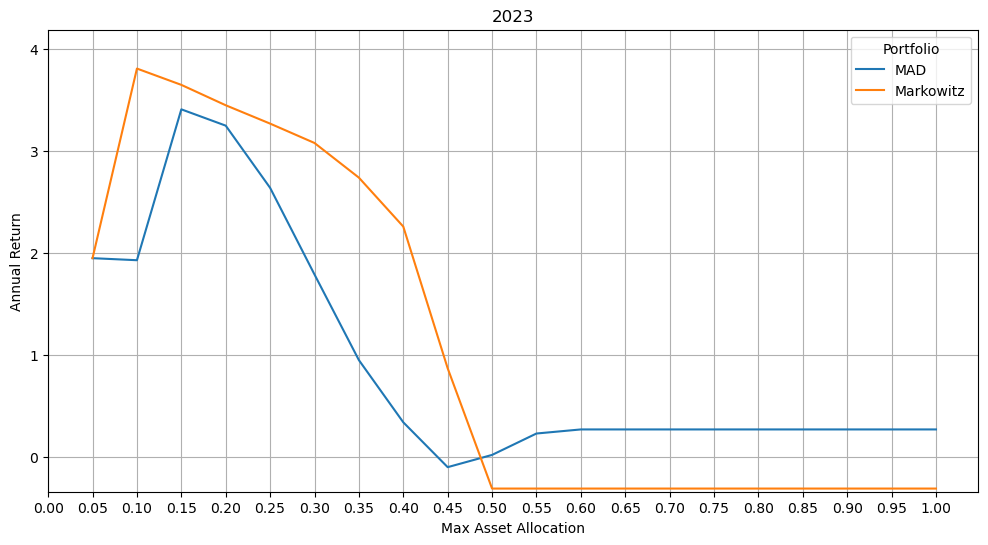

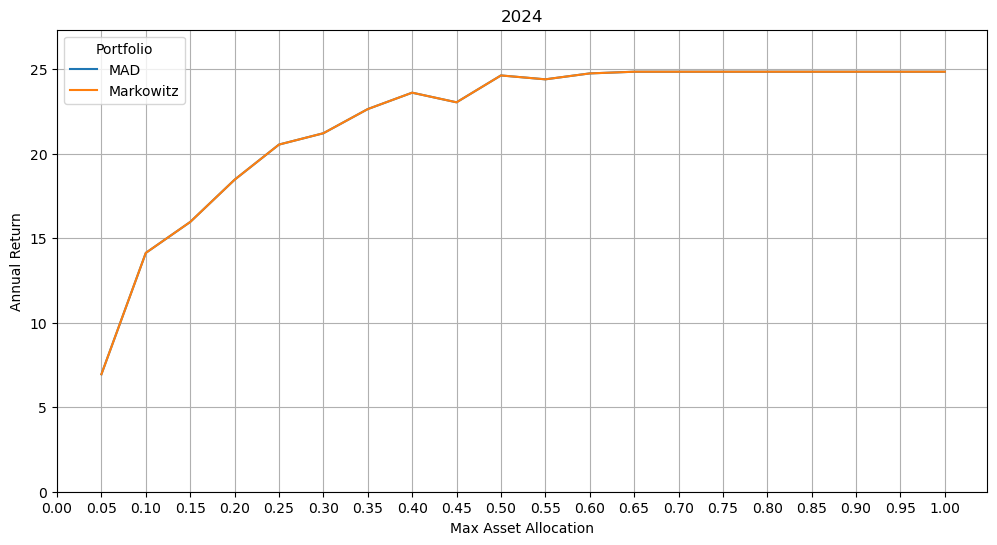

In [8]:
for year in range(2020, 2024 + 1):
    delta_df = pd.DataFrame(delta_dict)
    delta_df = pd.DataFrame(delta_df.loc[year]).reset_index()
    delta_df.columns = ['Max Alloc', 'Portfolio', 'Delta Return']
    delta_df = delta_df.pivot(index='Max Alloc', columns='Portfolio', values='Delta Return')
    delta_df.plot.line(figsize=(12,6))

    plt.title(year)
    plt.xticks([0] + list(delta_df.index.values))
    plt.xlabel("Max Asset Allocation")
    plt.ylim([1.1 * min(0, np.min(delta_df.values).item()), 
              1.1 * max(0, np.max(delta_df.values).item())])
    plt.ylabel("Annual Return")
    plt.grid()
    plt.show()